In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the datasets with appropriate encoding
drink_menu_df = pd.read_csv('/content/starbucks_drinkMenu_expanded.csv')
drink_nutr_df = pd.read_csv('/content/starbucks-menu-nutrition-drinks.csv')
food_nutr_df = pd.read_csv('/content/starbucks-menu-nutrition-food.csv', encoding='utf-16')

# Display basic information and shape of the datasets
print("Drink Menu Shape:", drink_menu_df.shape)
print("Drink Nutrition Shape:", drink_nutr_df.shape)
print("Food Nutrition Shape:", food_nutr_df.shape)

print("\n--- Drink Menu Columns ---")
print(drink_menu_df.columns.tolist())

display(drink_menu_df.head(3))

Drink Menu Shape: (242, 18)
Drink Nutrition Shape: (177, 7)
Food Nutrition Shape: (113, 6)

--- Drink Menu Columns ---
['Beverage_category', 'Beverage', 'Beverage_prep', 'Calories', ' Total Fat (g)', 'Trans Fat (g) ', 'Saturated Fat (g)', ' Sodium (mg)', ' Total Carbohydrates (g) ', 'Cholesterol (mg)', ' Dietary Fibre (g)', ' Sugars (g)', ' Protein (g) ', 'Vitamin A (% DV) ', 'Vitamin C (% DV)', ' Calcium (% DV) ', 'Iron (% DV) ', 'Caffeine (mg)']


,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0%,0%,0%,0%,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0%,0%,0%,0%,260
2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,0%,0%,330


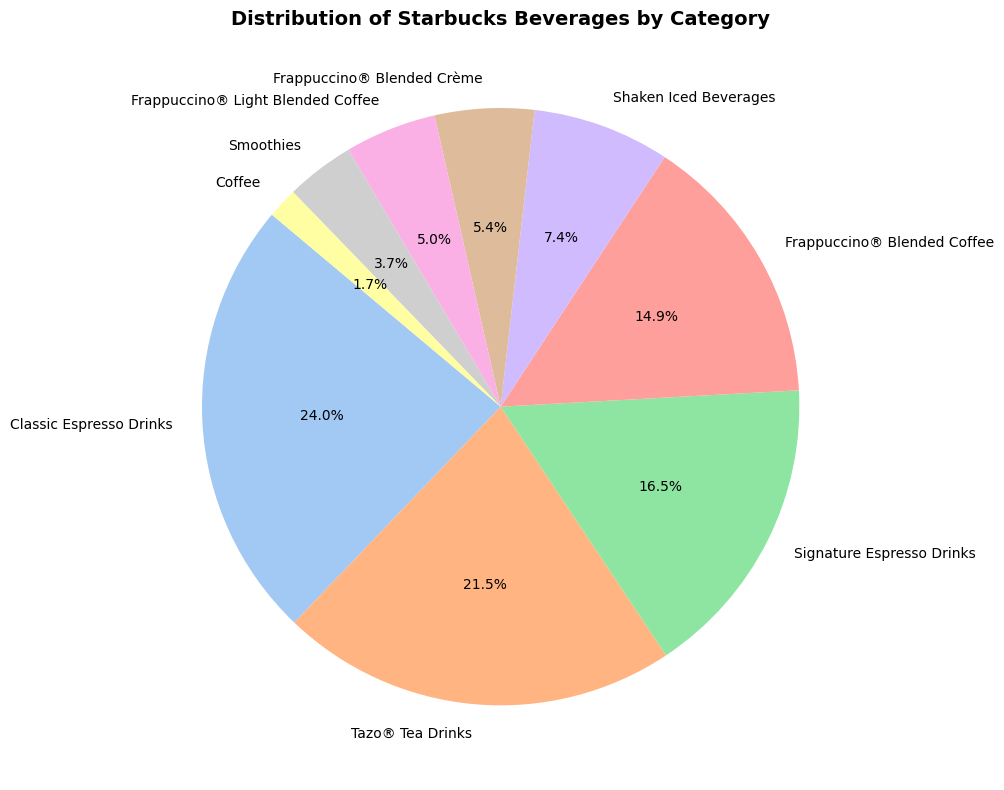

In [2]:
# Calculate category distribution
category_counts = drink_menu_df['Beverage_category'].value_counts()

# Create a pie chart
plt.figure(figsize=(10, 8))
plt.pie(
    category_counts,
    labels=category_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('pastel', len(category_counts))
)
plt.title('Distribution of Starbucks Beverages by Category', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Preparing Data and Training a Decision Tree Classifier
We will build a machine learning model using a **Decision Tree Classifier** to classify the `Beverage_category` of a beverage based on its nutritional components (Calories, Fat, Sodium, Carbs, Cholesterol, Fiber, Sugars, Protein, and Caffeine).

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

# Clean up column names (remove leading/trailing spaces)
drink_menu_df.columns = drink_menu_df.columns.str.strip()

# Select numerical nutritional features
features = [
    'Calories', 'Total Fat (g)', 'Sodium (mg)',
    'Total Carbohydrates (g)', 'Cholesterol (mg)',
    'Dietary Fibre (g)', 'Sugars (g)', 'Protein (g)'
]

# Clean selected feature columns (ensure they are numeric)
X = drink_menu_df[features].copy()
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors='coerce')

# Fill any missing values with the median of each column
X = X.fillna(X.median())

# Define the target variable
y = drink_menu_df['Beverage_category']

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialize and train the Decision Tree Classifier
clf = DecisionTreeClassifier(random_state=42, max_depth=5)
clf.fit(X_train, y_train)

# Make predictions on test data
y_pred = clf.predict(X_test)

# Generate and print classification report
report = classification_report(y_test, y_pred, zero_division=0)
print("--- Model Accuracy: {:.2f}% ---\n".format(accuracy_score(y_test, y_pred) * 100))
print("--- Classification Report ---")
print(report)

--- Model Accuracy: 55.10% ---

--- Classification Report ---
                                   precision    recall  f1-score   support

          Classic Espresso Drinks       1.00      0.33      0.50        12
                           Coffee       1.00      1.00      1.00         1
      Frappuccino® Blended Coffee       0.64      1.00      0.78         7
       Frappuccino® Blended Crème       0.00      0.00      0.00         3
Frappuccino® Light Blended Coffee       0.00      0.00      0.00         2
            Shaken Iced Beverages       1.00      0.75      0.86         4
        Signature Espresso Drinks       0.14      0.12      0.13         8
                        Smoothies       1.00      1.00      1.00         2
                 Tazo® Tea Drinks       0.43      0.90      0.58        10

                         accuracy                           0.55        49
                        macro avg       0.58      0.57      0.54        49
                     weighted avg   

In [5]:
# Show actual vs predicted side-by-side
comparison_df = pd.DataFrame({
    'Actual Category': y_test,
    'Predicted Category': y_pred
})
display(comparison_df.head(15))

,Actual Category,Predicted Category
197,Frappuccino® Blended Coffee,Frappuccino® Blended Coffee
88,Signature Espresso Drinks,Tazo® Tea Drinks
42,Classic Espresso Drinks,Classic Espresso Drinks
32,Classic Espresso Drinks,Tazo® Tea Drinks
107,Tazo® Tea Drinks,Tazo® Tea Drinks
11,Classic Espresso Drinks,Signature Espresso Drinks
52,Classic Espresso Drinks,Classic Espresso Drinks
155,Shaken Iced Beverages,Shaken Iced Beverages
2,Coffee,Coffee
62,Signature Espresso Drinks,Tazo® Tea Drinks


### Improving Model Accuracy
We will improve the accuracy of our Decision Tree Classifier by:
1. **Feature Engineering**: Incorporating and one-hot encoding the `Beverage_prep` column.
2. **Hyperparameter Tuning**: Using `GridSearchCV` to find the best tree depth, split criteria, and minimum sample splits.

In [6]:
from sklearn.model_selection import GridSearchCV

# Keep numerical nutritional features
num_features = [
    'Calories', 'Total Fat (g)', 'Sodium (mg)',
    'Total Carbohydrates (g)', 'Cholesterol (mg)',
    'Dietary Fibre (g)', 'Sugars (g)', 'Protein (g)'
]

# Ensure numerical columns are correctly parsed and filled
X_num = drink_menu_df[num_features].copy()
for col in X_num.columns:
    X_num[col] = pd.to_numeric(X_num[col], errors='coerce')
X_num = X_num.fillna(X_num.median())

# One-hot encode 'Beverage_prep' to capture drink sizes and milk options
X_prep = pd.get_dummies(drink_menu_df['Beverage_prep'], drop_first=True)

# Combine numerical and encoded categorical features
X_improved = pd.concat([X_num, X_prep], axis=1)
y_improved = drink_menu_df['Beverage_category']

# Split the dataset 80/20
X_train_imp, X_test_imp, y_train_imp, y_test_imp = train_test_split(
    X_improved, y_improved, test_size=0.2, random_state=42, stratify=y_improved
)

# Set up parameter grid for Grid Search
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 7, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Run GridSearchCV
grid_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, n_jobs=-1)
grid_search.fit(X_train_imp, y_train_imp)

# Train best estimator
best_clf = grid_search.best_estimator_
y_pred_imp = best_clf.predict(X_test_imp)

# Output performance metrics
print("Best Parameters Found:", grid_search.best_params_)
print("\n--- Improved Model Accuracy: {:.2f}% ---\n".format(accuracy_score(y_test_imp, y_pred_imp) * 100))
print("--- Improved Classification Report ---")
print(classification_report(y_test_imp, y_pred_imp, zero_division=0))

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


Best Parameters Found: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2}

--- Improved Model Accuracy: 57.14% ---

--- Improved Classification Report ---
                                   precision    recall  f1-score   support

          Classic Espresso Drinks       0.55      0.50      0.52        12
                           Coffee       1.00      1.00      1.00         1
      Frappuccino® Blended Coffee       0.67      0.86      0.75         7
       Frappuccino® Blended Crème       0.00      0.00      0.00         3
Frappuccino® Light Blended Coffee       1.00      0.50      0.67         2
            Shaken Iced Beverages       0.75      0.75      0.75         4
        Signature Espresso Drinks       0.38      0.38      0.38         8
                        Smoothies       1.00      0.50      0.67         2
                 Tazo® Tea Drinks       0.54      0.70      0.61        10

                         accuracy                         

In [7]:
# Show actual vs predicted side-by-side for the improved model
improved_comparison_df = pd.DataFrame({
    'Actual Category': y_test_imp,
    'Predicted Category': y_pred_imp
})
display(improved_comparison_df.head(15))

,Actual Category,Predicted Category
197,Frappuccino® Blended Coffee,Frappuccino® Blended Coffee
88,Signature Espresso Drinks,Classic Espresso Drinks
42,Classic Espresso Drinks,Classic Espresso Drinks
32,Classic Espresso Drinks,Signature Espresso Drinks
107,Tazo® Tea Drinks,Tazo® Tea Drinks
11,Classic Espresso Drinks,Tazo® Tea Drinks
52,Classic Espresso Drinks,Classic Espresso Drinks
155,Shaken Iced Beverages,Shaken Iced Beverages
2,Coffee,Coffee
62,Signature Espresso Drinks,Classic Espresso Drinks


In [8]:
import joblib

# Save the best estimator model to a file
model_filename = 'starbucks_decision_tree_model.joblib'
joblib.dump(best_clf, model_filename)
print(f"Model successfully saved as: '{model_filename}'")

Model successfully saved as: 'starbucks_decision_tree_model.joblib'
